# Parcial práctico: Red de estaciones de transporte con grafos, BFS y DFS




In [ ]:
# @title Datos del estudiante
nombre_estudiante = "Anderson Varela"
carnet = 1000116567



## 1) Descripción del problema

Se necesita representar una red de estaciones de transporte. Cada estación es un vértice y cada conexión directa es una arista. El programa debe mostrar las conexiones, recorrer la red con BFS y DFS, encontrar una ruta con el menor número de conexiones y permitir agregar una estación nueva.

El grafo es **no dirigido**, por lo que cada conexión se guarda en los dos sentidos. Para evitar conexiones duplicadas, se comprueba si la estación vecina ya está registrada.


## 2) Requerimientos

Funcionales
1. Guardar las estaciones y sus conexiones mediante una lista de adyacencia.
2. Mostrar las estaciones y sus vecinos directos.
3. Ejecutar BFS desde Central, mostrando el orden de visita y el nivel de cada estación.
4. Ejecutar DFS desde Central.
5. Permitir recorrer BFS y DFS desde una estación indicada y reportar si no existe.
6. Encontrar con BFS la ruta con menor cantidad de conexiones entre un origen y un destino.
7. Agregar una nueva estación y conectarla con al menos dos estaciones existentes.
8. No repetir estaciones durante un recorrido ni conexiones dentro de la lista.

No funcionales
1. El código debe ser sencillo de leer y mantener.
2. Debe usar Python básico y no depender de librerías de grafos.
3. Debe mostrar mensajes claros cuando una estación no exista o no haya ruta.
4. Los recorridos deben terminar visitando cada estación como máximo una vez.


## 3) Historias de usuario

1. **Como usuario**, quiero ver las conexiones de cada estación para conocer a cuáles puedo llegar directamente.  
   **Criterio de aceptación:** se imprime cada estación y su lista de vecinos.

2. **Como usuario**, quiero recorrer la red con BFS para conocer las estaciones por niveles.  
   **Criterio de aceptación:** comienza en la estación indicada, cada estación se visita una vez y se muestra su nivel.

3. **Como usuario**, quiero recorrer la red con DFS para explorar una ruta antes de retroceder.  
   **Criterio de aceptación:** se muestra un orden de visita sin repetir estaciones.

4. **Como usuario**, quiero encontrar una ruta entre dos estaciones con el menor número de conexiones.  
   **Criterio de aceptación:** si existe una ruta, se muestra la secuencia y la cantidad de conexiones; si no, se informa.

5. **Como usuario**, quiero agregar una estación nueva conectada con estaciones existentes.  
   **Criterio de aceptación:** la nueva estación aparece en la lista de adyacencia y las conexiones funcionan en ambos sentidos.


## 4) Diagrama de flujo

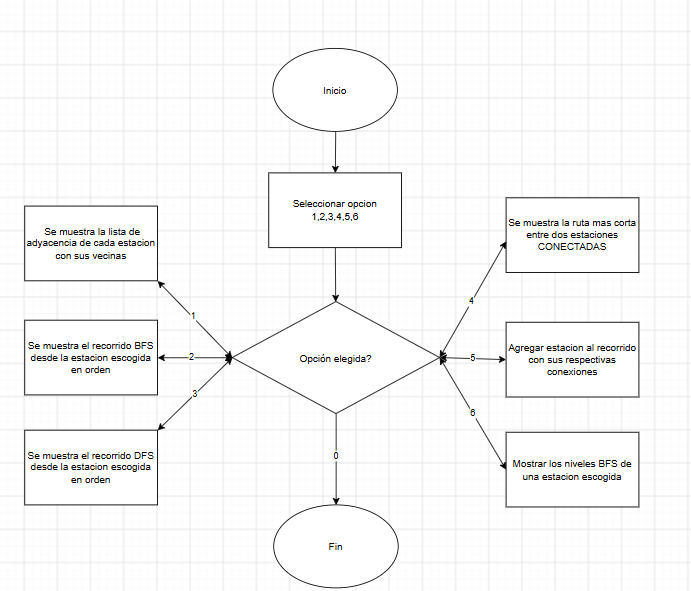


El programa inicia y muestra el menú interactivo preguntandole al usuario que opcion desea escoger,cada una con sus respectivos numeros,cada opcion tiene sus funciones especificas y muestra algo diferente cada vez dando diferentes opciones como añadir estaciones,ver sus vecinas y conexiones etc.Si el usuario presiona 0 el programa finalizará


### 5) Análisis de complejidad

Los vertices se revisan a lo sumo dos veces por pasada del recorrido BFS o DFS y si se añaden estaciones no cambia la forma en la que se realiza el recorrido,en un grafo dirigido el mejor caso es O(1x) siendo lineal el recorrido cada vez y en el peor caso de un no dirigido donde cada vertice se revisa maximo dos veces sería de O(2x) siendo este el peor caso pero sin dejar de ser lineal

MEJOR CASO:

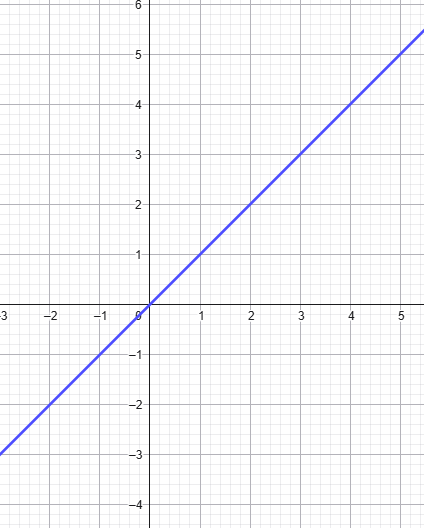

PEOR CASO:

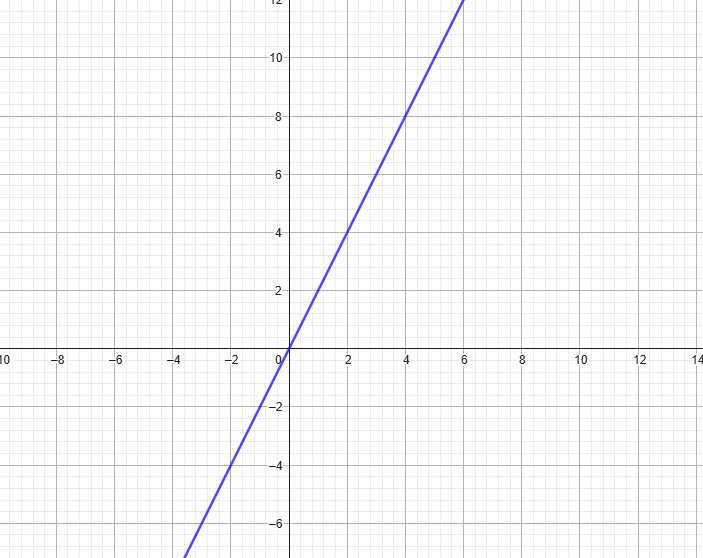



## 6) Código funcional

El código siguiente desarrolla los puntos del parcial. Para los ejemplos se usan las estaciones del enunciado y, al final, se agrega `Aeropuerto` conectado con `Terminal` y `Hospital`.


In [4]:


grafo = {
    "Central": ["Norte", "Museo"],
    "Norte": ["Central", "Parque", "Universidad"],
    "Museo": ["Central", "Hospital"],
    "Parque": ["Norte"],
    "Universidad": ["Norte", "Terminal"],
    "Hospital": ["Museo", "Terminal"],
    "Terminal": ["Universidad", "Hospital"]
}


def mostrar_grafo(grafo):
    for estacion in grafo:
        print(estacion + ": " + ", ".join(grafo[estacion]))


def bfs(grafo, inicio):
    if inicio not in grafo:
        return None

    cola = [inicio]
    visitados = [inicio]
    niveles = {inicio: 0}
    orden = []

    while len(cola) > 0:
        actual = cola.pop(0)
        orden.append(actual)

        for vecino in grafo[actual]:
            if vecino not in visitados:
                visitados.append(vecino)
                niveles[vecino] = niveles[actual] + 1
                cola.append(vecino)

    return orden, niveles


def dfs(grafo, inicio):
    if inicio not in grafo:
        return None

    visitados = []
    orden = []

    def visitar(estacion):
        visitados.append(estacion)
        orden.append(estacion)

        for vecino in grafo[estacion]:
            if vecino not in visitados:
                visitar(vecino)

    visitar(inicio)
    return orden


def buscar_ruta(grafo, origen, destino):
    if origen not in grafo or destino not in grafo:
        return None

    cola = [origen]
    visitados = [origen]
    anterior = {origen: None}

    while len(cola) > 0:
        actual = cola.pop(0)

        if actual == destino:
            break

        for vecino in grafo[actual]:
            if vecino not in visitados:
                visitados.append(vecino)
                anterior[vecino] = actual
                cola.append(vecino)

    if destino not in anterior:
        return None

    ruta = []
    actual = destino

    while actual is not None:
        ruta.insert(0, actual)
        actual = anterior[actual]

    return ruta


def agregar_estacion(grafo, nueva, conexiones):
    if nueva == "":
        print("El nombre de la estacion no puede estar vacio.")
        return

    if nueva in grafo:
        print("La estacion ya existe.")
        return

    if len(conexiones) < 2:
        print("Debe conectarse con al menos dos estaciones.")
        return

    for estacion in conexiones:
        if estacion not in grafo:
            print("No existe la estacion:", estacion)
            return

    grafo[nueva] = []

    for estacion in conexiones:
        if estacion not in grafo[nueva]:
            grafo[nueva].append(estacion)

        if nueva not in grafo[estacion]:
            grafo[estacion].append(nueva)

    print("Estacion agregada correctamente.")


def menu():
    while True:
        print("\n========== MENU PRINCIPAL ==========")
        print("1. Mostrar lista de adyacencia")
        print("2. Recorrido BFS")
        print("3. Recorrido DFS")
        print("4. Buscar ruta mas corta")
        print("5. Agregar estacion")
        print("6. Mostrar niveles BFS")
        print("0. Salir")
        print("====================================")

        opcion = input("Seleccione una opcion: ").strip()

        if opcion == "1":
            print("\nPUNTO 1. LISTA DE ADYACENCIA")
            mostrar_grafo(grafo)

        elif opcion == "2":
            print("\nPUNTO 2. RECORRIDO BFS")
            inicio = input("Desde que estacion desea iniciar: ").strip()

            resultado = bfs(grafo, inicio)

            if resultado is None:
                print("La estacion no existe.")
            else:
                print("Orden BFS:", " -> ".join(resultado[0]))

        elif opcion == "3":
            print("\nPUNTO 3. RECORRIDO DFS")
            inicio = input("Desde que estacion desea iniciar: ").strip()

            resultado = dfs(grafo, inicio)

            if resultado is None:
                print("La estacion no existe.")
            else:
                print("Orden DFS:", " -> ".join(resultado))

        elif opcion == "4":
            print("\nPUNTO 4. RUTA MAS CORTA")
            origen = input("Estacion de origen: ").strip()
            destino = input("Estacion de destino: ").strip()

            ruta = buscar_ruta(grafo, origen, destino)

            if ruta is None:
                print("No existe una ruta entre esas estaciones.")
            else:
                print("Ruta encontrada:", " -> ".join(ruta))
                print("Cantidad de conexiones:", len(ruta) - 1)

        elif opcion == "5":
            print("\nPUNTO 5. AGREGAR ESTACION")
            nueva = input("Nombre de la nueva estacion: ").strip()

            print("Estaciones existentes:")
            for estacion in grafo:
                print(estacion)

            entrada = input(
                "Escriba al menos dos conexiones separadas por comas: "
            )

            conexiones = []
            partes = entrada.split(",")

            for estacion in partes:
                estacion = estacion.strip()

                if estacion != "" and estacion not in conexiones:
                    conexiones.append(estacion)

            agregar_estacion(grafo, nueva, conexiones)

        elif opcion == "6":
            print("\nPUNTO 6. NIVELES BFS")
            inicio = input("Desde que estacion desea iniciar: ").strip()

            resultado = bfs(grafo, inicio)

            if resultado is None:
                print("La estacion no existe.")
            else:
                niveles = resultado[1]

                for nivel in range(len(grafo)):
                    estaciones_nivel = []

                    for estacion in niveles:
                        if niveles[estacion] == nivel:
                            estaciones_nivel.append(estacion)

                    if len(estaciones_nivel) > 0:
                        print(
                            "Nivel", nivel, ":",
                            ", ".join(estaciones_nivel)
                        )

        elif opcion == "0":
            print("Programa finalizado.")
            break

        else:
            print("Opcion incorrecta. Intente nuevamente.")



menu()



========== MENU PRINCIPAL ==========
1. Mostrar lista de adyacencia
2. Recorrido BFS
3. Recorrido DFS
4. Buscar ruta mas corta
5. Agregar estacion
6. Mostrar niveles BFS
0. Salir

PUNTO 5. AGREGAR ESTACION
Estaciones existentes:
Central
Norte
Museo
Parque
Universidad
Hospital
Terminal
Estacion agregada correctamente.

========== MENU PRINCIPAL ==========
1. Mostrar lista de adyacencia
2. Recorrido BFS
3. Recorrido DFS
4. Buscar ruta mas corta
5. Agregar estacion
6. Mostrar niveles BFS
0. Salir

PUNTO 1. LISTA DE ADYACENCIA
Central: Norte, Museo
Norte: Central, Parque, Universidad
Museo: Central, Hospital
Parque: Norte
Universidad: Norte, Terminal, Elefante
Hospital: Museo, Terminal
Terminal: Universidad, Hospital, Elefante
Elefante: Universidad, Terminal

========== MENU PRINCIPAL ==========
1. Mostrar lista de adyacencia
2. Recorrido BFS
3. Recorrido DFS
4. Buscar ruta mas corta
5. Agregar estacion
6. Mostrar niveles BFS
0. Salir
Programa finalizado.


## 7) Tests aplicados

Se prueban las conexiones iniciales, los recorridos, la ruta mínima, los errores de estaciones inexistentes y la incorporación de la nueva estación. Los `assert` generan un error si alguna condición no se cumple.


In [7]:
# Pruebas automáticas básicas
grafo_prueba = {
    "Central": ["Norte", "Museo"],
    "Norte": ["Central", "Parque", "Universidad"],
    "Museo": ["Central", "Hospital"],
    "Parque": ["Norte"],
    "Universidad": ["Norte", "Terminal"],
    "Hospital": ["Museo", "Terminal"],
    "Terminal": ["Universidad", "Hospital"]
}

assert bfs(grafo_prueba, "Central")[0][0] == "Central"
assert set(bfs(grafo_prueba, "Central")[0]) == set(grafo_prueba.keys())
assert len(dfs(grafo_prueba, "Central")) == len(grafo_prueba)
assert buscar_ruta(grafo_prueba, "Central", "Terminal") == ["Central", "Norte", "Universidad", "Terminal"]
assert buscar_ruta(grafo_prueba, "Central", "EstacionQueNoExiste") is None
assert bfs(grafo_prueba, "EstacionQueNoExiste") is None

agregar_estacion(grafo_prueba, "Aeropuerto", ["Terminal", "Hospital"])
assert "Aeropuerto" in grafo_prueba
assert "Aeropuerto" in grafo_prueba["Terminal"]
assert "Aeropuerto" in grafo_prueba["Hospital"]
assert "Terminal" in grafo_prueba["Aeropuerto"]
assert "Hospital" in grafo_prueba["Aeropuerto"]

print("Todas las pruebas pasaron correctamente.")


Estacion agregada correctamente.
Todas las pruebas pasaron correctamente.
